In [1]:
!pip install -q transformers datasets evaluate peft accelerate bitsandbytes


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 11.8 MB/s eta 0:00:00


In [2]:
import torch
import time
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model, TaskType
import evaluate
import numpy as np

In [8]:
dataset = load_dataset("imdb")
tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2-0.5B",
    trust_remote_code=True
)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

In [9]:
def preprocess(examples):
    return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=512)

tokenized = dataset.map(preprocess, batched=True)
tokenized = tokenized.rename_column("label", "labels")
tokenized.set_format("torch")

accuracy = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy.compute(predictions=predictions, references=labels)

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

In [10]:
print("=== Starting FULL FINE-TUNING ===")
model_full = AutoModelForSequenceClassification.from_pretrained(
    "Qwen/Qwen2-0.5B",
    num_labels=2,
    torch_dtype=torch.bfloat16,
    trust_remote_code=True
)

# === THE TWO LINES THAT FIX YOUR ERROR ===
model_full.config.pad_token_id = tokenizer.pad_token_id
model_full.config.use_cache = False          # saves memory during training

model_full.gradient_checkpointing_enable()

training_args_full = TrainingArguments(
    output_dir="./qwen2-full",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=5e-5,
    eval_steps=500,
    logging_steps=100,
    bf16=True,
    report_to="none",
)

trainer_full = Trainer(
    model=model_full,
    args=training_args_full,
    train_dataset=tokenized["train"].shuffle(seed=42).select(range(10000)),
    eval_dataset=tokenized["test"].shuffle(seed=42).select(range(2000)),
    compute_metrics=compute_metrics,
)

start = time.time()
torch.cuda.reset_peak_memory_stats()
trainer_full.train()
full_time = time.time() - start
full_mem = torch.cuda.max_memory_allocated() / 1e9
full_acc = trainer_full.evaluate()["eval_accuracy"]

print(f"FULL → Time: {full_time/60:.1f} min | Memory: {full_mem:.1f} GB | Acc: {full_acc*100:.1f}%")
del model_full, trainer_full
torch.cuda.empty_cache()

=== Starting FULL FINE-TUNING ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
100,1.376559
200,0.634830
300,0.524644
400,0.463594
500,0.362578
600,0.366712


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

FULL → Time: 116.3 min | Memory: 5.9 GB | Acc: 94.9%


In [12]:
print("=== Starting LoRA (PEFT) ===")
model_lora = AutoModelForSequenceClassification.from_pretrained(
    "Qwen/Qwen2-0.5B",
    num_labels=2,
    torch_dtype=torch.bfloat16,
    trust_remote_code=True
)

model_lora.config.pad_token_id = tokenizer.pad_token_id
model_lora.config.use_cache = False

peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
)
model_lora = get_peft_model(model_lora, peft_config)
model_lora.print_trainable_parameters()

training_args_lora = TrainingArguments(
    output_dir="./qwen2-lora",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=5e-5,
    eval_steps=500,
    logging_steps=100,
    bf16=True,
    report_to="none",
)

trainer_lora = Trainer(
    model=model_lora,
    args=training_args_lora,
    train_dataset=tokenized["train"].shuffle(seed=42).select(range(10000)),
    eval_dataset=tokenized["test"].shuffle(seed=42).select(range(2000)),
    compute_metrics=compute_metrics,
)

start = time.time()
torch.cuda.reset_peak_memory_stats()
trainer_lora.train()
lora_time = time.time() - start
lora_mem = torch.cuda.max_memory_allocated() / 1e9
lora_acc = trainer_lora.evaluate()["eval_accuracy"]

print(f"LoRA → Time: {lora_time/60:.1f} min | Memory: {lora_mem:.1f} GB | Acc: {lora_acc*100:.1f}%")

=== Starting LoRA (PEFT) ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,083,136 || all params: 495,117,696 || trainable%: 0.2188


Step,Training Loss
100,1.702264
200,0.794872
300,0.660907
400,0.654801
500,0.571885
600,0.555279


LoRA → Time: 69.6 min | Memory: 9.8 GB | Acc: 93.5%


In [13]:
!pip install -q matplotlib

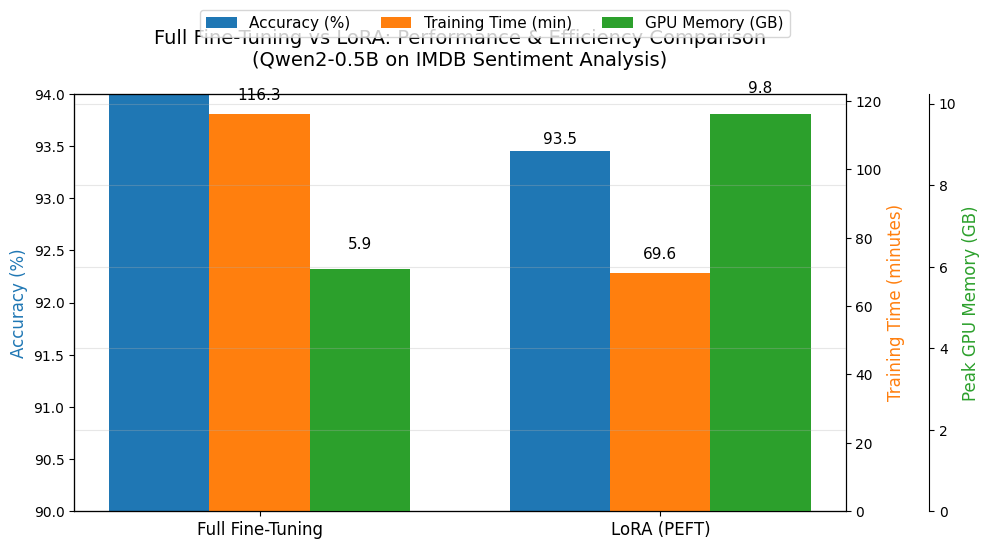

Graph saved as 'full_vs_lora_comparison.png' — download it and insert into your report!


In [14]:
import matplotlib.pyplot as plt

full_acc = full_acc * 100
lora_acc = lora_acc * 100
full_time = full_time / 60
lora_time = lora_time / 60
full_mem = full_mem
lora_mem = lora_mem

# Data for plotting
methods = ['Full Fine-Tuning', 'LoRA (PEFT)']
accuracy = [full_acc, lora_acc]
time_min = [full_time, lora_time]
memory_gb = [full_mem, lora_mem]

x = np.arange(len(methods))
width = 0.25

fig, ax1 = plt.subplots(figsize=(10, 6))

# Accuracy bars
bars1 = ax1.bar(x - width, accuracy, width, label='Accuracy (%)', color='#1f77b4')
ax1.set_ylabel('Accuracy (%)', color='#1f77b4', fontsize=12)
ax1.set_ylim(90, 94)

# Time bars (secondary axis)
ax2 = ax1.twinx()
bars2 = ax2.bar(x, time_min, width, label='Training Time (min)', color='#ff7f0e')
ax2.set_ylabel('Training Time (minutes)', color='#ff7f0e', fontsize=12)

# Memory bars
ax3 = ax1.twinx()
ax3.spines['right'].set_position(('outward', 60))
bars3 = ax3.bar(x + width, memory_gb, width, label='GPU Memory (GB)', color='#2ca02c')
ax3.set_ylabel('Peak GPU Memory (GB)', color='#2ca02c', fontsize=12)

# Labels and title
ax1.set_title('Full Fine-Tuning vs LoRA: Performance & Efficiency Comparison\n(Qwen2-0.5B on IMDB Sentiment Analysis)', fontsize=14, pad=20)
ax1.set_xticks(x)
ax1.set_xticklabels(methods, fontsize=12)

# Add value labels on bars
def autolabel(bars, ax, offset=0):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3 + offset),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11)

autolabel(bars1, ax1)
autolabel(bars2, ax2, 5)
autolabel(bars3, ax3, 10)

# Legend
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.92), ncol=3, fontsize=11)
0
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.grid(axis='y', alpha=0.3)

# Save for report
plt.savefig('full_vs_lora_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("Graph saved as 'full_vs_lora_comparison.png' — download it and insert into your report!")